# 01 – Data quality and exploratory analysis

**ML Project – Early Detection of Students at Risk of Dropout** · Week 2

Module owner: **Timéo Brajon** · Group **AALT** (DIA4): Léo Chen, Adam Gaabi, Timéo Brajon, Axel Warot

Raw data: UCI *Predict Students' Dropout and Academic Success* (id 697), `data/raw/data.csv`, semicolon-separated. Download: https://archive.ics.uci.edu/dataset/697

In [1]:
import sys,warnings
warnings.filterwarnings("ignore")
sys.path.insert(0,"../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from features import *
pd.set_option("display.width",160)
pd.set_option("display.max_columns",40)

In [2]:
raw=pd.read_csv("../data/raw/data.csv",sep=";")
print(raw.shape)
print("Column names with hidden whitespace:",[c for c in raw.columns if c!=c.strip()])
d=load_raw("../data/raw/data.csv")
print("Missing values:",d.isna().sum().sum(),"| Duplicated rows:",d.duplicated().sum())
d.dtypes.value_counts()

(4424, 37)
Column names with hidden whitespace: []
Missing values: 0 | Duplicated rows: 0


int64      29
float64     7
str         1
Name: count, dtype: int64

## 1. Variable types
All features are stored as numbers, but many of them are **nominal codes** (course, application mode, parents' occupation...). Treating them as numeric would create a false order, so they must be one-hot encoded.

In [3]:
groups={"nominal":NOMINAL,"binary":BINARY,"numeric (enrollment)":NUMERIC_ENROLL,"semester 1":SEM1,"semester 2":SEM2}
pd.DataFrame([{"group":g,"n":len(c),"columns":", ".join(c),"unique values":", ".join(str(d[x].nunique()) for x in c)} for g,c in groups.items()])

,group,n,columns,unique values
0,nominal,9,"marital_status, application_mode, course, prev...","6, 18, 17, 17, 21, 29, 34, 32, 46"
1,binary,8,"daytime_attendance, displaced, special_needs, ...","2, 2, 2, 2, 2, 2, 2, 2"
2,numeric (enrollment),7,"application_order, previous_qualification_grad...","8, 101, 620, 46, 10, 9, 10"
3,semester 1,6,"sem1_credited, sem1_enrolled, sem1_evaluations...","21, 23, 35, 23, 805, 11"
4,semester 2,6,"sem2_credited, sem2_enrolled, sem2_evaluations...","19, 22, 30, 20, 786, 10"


## 2. Target distribution

          count  share
target                
Dropout    1421  0.321
Enrolled    794  0.179
Graduate   2209  0.499


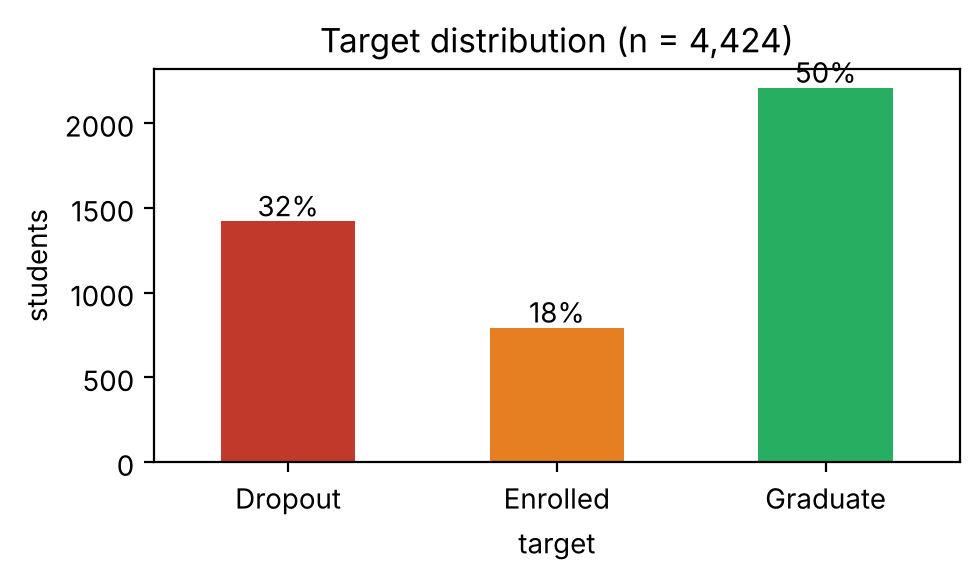

In [4]:
t=d[TARGET].value_counts().reindex(CLASSES)
print(pd.DataFrame({"count":t,"share":(t/len(d)).round(3)}))
ax=t.plot.bar(color=["#c0392b","#e67e22","#27ae60"],figsize=(5,3),rot=0)
ax.set_ylabel("students");ax.set_title("Target distribution (n = 4,424)")
for i,v in enumerate(t):ax.text(i,v+30,f"{v/len(d):.0%}",ha="center")
plt.tight_layout();plt.savefig("../report/figures/target.png",dpi=150);plt.show()

The classes are imbalanced (50 / 32 / 18 %). Accuracy is misleading here: we use **macro-F1** as the main metric and keep the split stratified.

## 3. Numeric variables and outliers

In [5]:
num=NUMERIC_ENROLL+SEM1+SEM2
q1,q3=d[num].quantile(.25),d[num].quantile(.75);iqr=q3-q1
out=((d[num]<q1-1.5*iqr)|(d[num]>q3+1.5*iqr)).sum()
pd.DataFrame({"min":d[num].min(),"median":d[num].median(),"max":d[num].max(),"IQR outliers":out,"% outliers":(out/len(d)*100).round(1)})

,min,median,max,IQR outliers,% outliers
application_order,0.00,1.000000,9.000000,541,12.2
previous_qualification_grade,95.00,133.100000,190.000000,179,4.0
admission_grade,95.00,126.100000,190.000000,86,1.9
age_at_enrollment,17.00,20.000000,70.000000,441,10.0
unemployment_rate,7.60,11.100000,16.200000,0,0.0
inflation_rate,-0.80,1.400000,3.700000,0,0.0
gdp,-4.06,0.320000,3.510000,0,0.0
sem1_credited,0.00,0.000000,20.000000,577,13.0
sem1_enrolled,0.00,6.000000,26.000000,424,9.6
sem1_evaluations,0.00,8.000000,45.000000,158,3.6


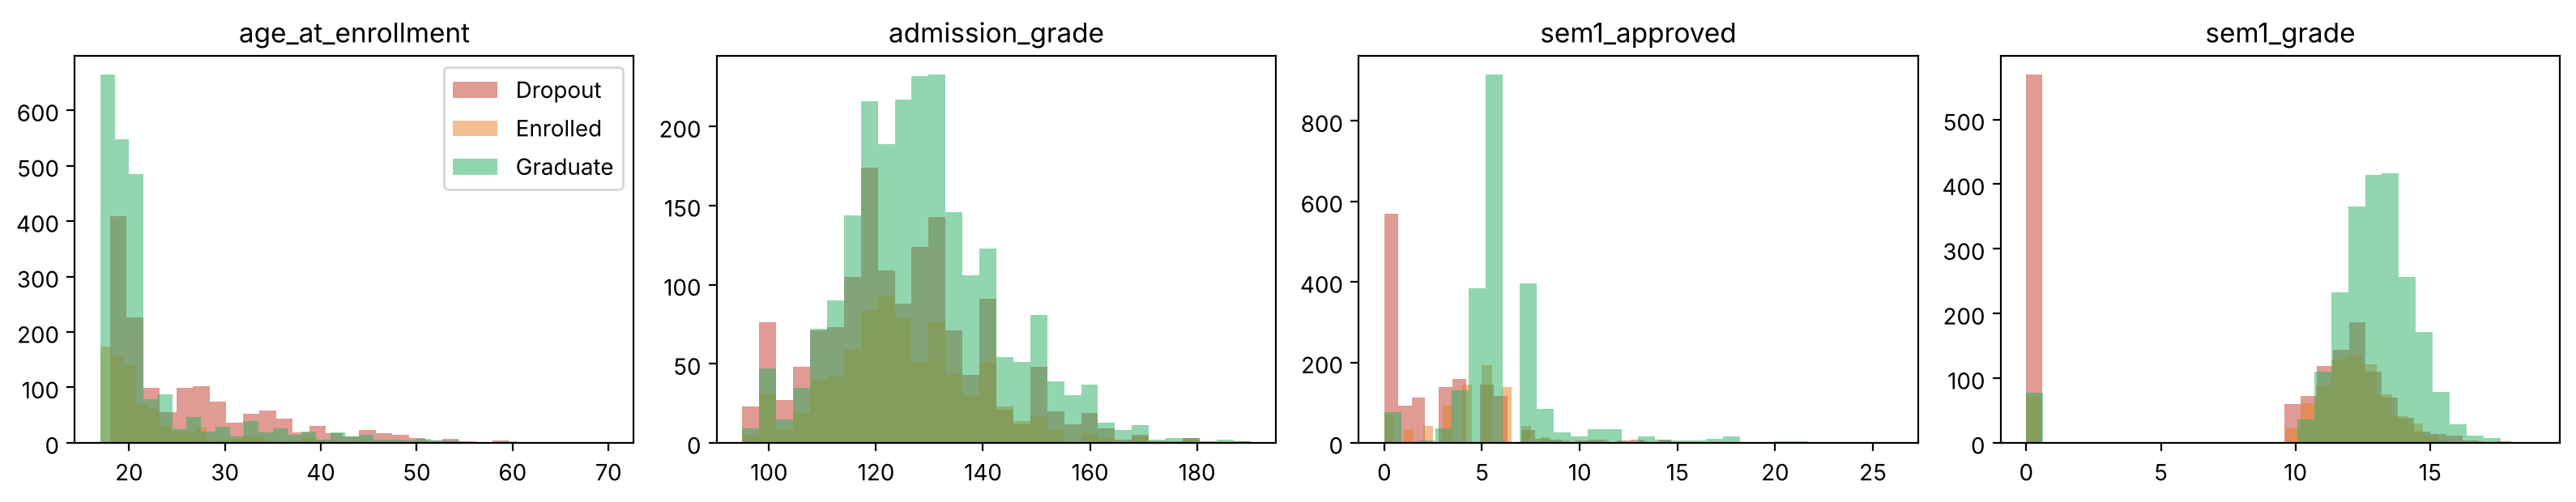

In [6]:
fig,ax=plt.subplots(1,4,figsize=(16,3.2))
for a,c in zip(ax,["age_at_enrollment","admission_grade","sem1_approved","sem1_grade"]):
    for k,col in zip(CLASSES,["#c0392b","#e67e22","#27ae60"]):a.hist(d.loc[d[TARGET]==k,c],bins=30,alpha=.5,label=k,color=col)
    a.set_title(c)
ax[0].legend();plt.tight_layout();plt.savefig("../report/figures/distributions.png",dpi=150);plt.show()

IQR "outliers" are real values, not errors: older students (up to 70), students with credited units from a previous degree, students with no unit evaluated. They carry information about the risk, so **we keep them**. The scaler is fitted on training folds only.

## 4. Zero grades in semester data

In [7]:
for k in ["sem1","sem2"]:
    print(k,"| enrolled = 0:",(d[f"{k}_enrolled"]==0).sum(),"| grade = 0:",(d[f"{k}_grade"]==0).sum())
pd.crosstab(d["sem1_grade"]==0,d[TARGET],normalize="index").round(2).rename(index={False:"sem1 grade > 0",True:"sem1 grade = 0"})

sem1 | enrolled = 0: 180 | grade = 0: 718
sem2 | enrolled = 0: 180 | grade = 0: 870


target,Dropout,Enrolled,Graduate
sem1_grade,,,
sem1 grade > 0,0.23,0.2,0.58
sem1 grade = 0,0.79,0.1,0.11


A grade of 0 means **no grade** (no unit evaluated or approved), not a real mark of 0/20. 80% of these students drop out. We add a `no_grade` flag and an `approval_rate` = approved / enrolled so that the model does not mix the two meanings.

## 5. Macro-economic variables

In [8]:
d.groupby(["unemployment_rate","inflation_rate","gdp"]).size().rename("students").reset_index()

,unemployment_rate,inflation_rate,gdp,students
0,7.6,2.6,0.32,571
1,8.9,1.4,3.51,368
2,9.4,-0.8,-3.12,533
3,10.8,1.4,1.74,525
4,11.1,0.6,2.02,414
5,12.4,0.5,1.79,445
6,12.7,3.7,-1.70,419
7,13.9,-0.3,0.79,390
8,15.5,2.8,-4.06,397
9,16.2,0.3,-0.92,362


The three macro-economic variables only take **10 distinct combinations**: they identify the enrollment year (cohort), not the student. They can act as a cohort proxy, which is a risk for generalisation to new years (see report).

## 6. Correlations

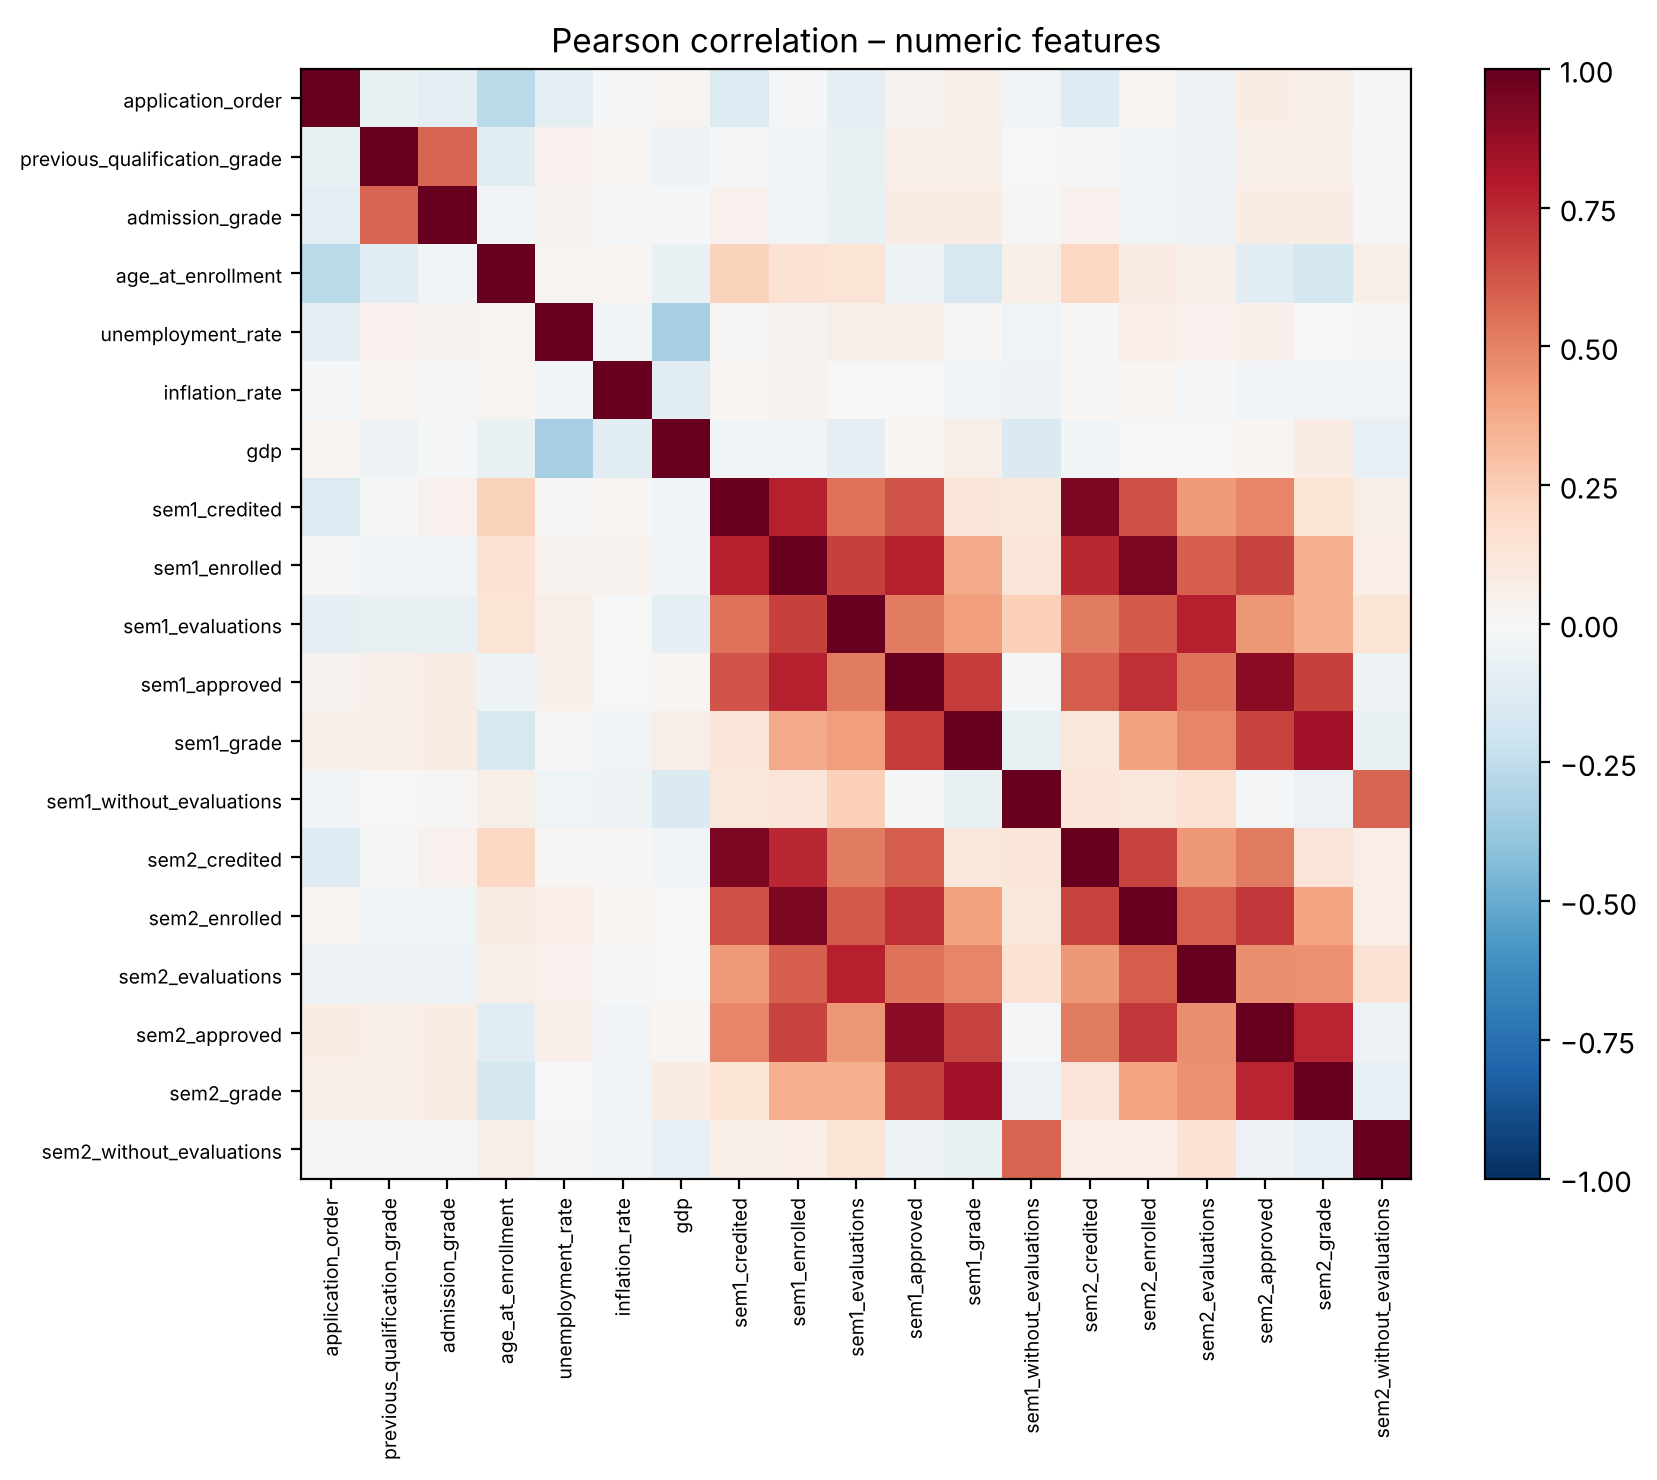

sem1_credited     sem2_credited       0.945
sem1_enrolled     sem2_enrolled       0.943
sem1_approved     sem2_approved       0.904
sem1_grade        sem2_grade          0.837
sem1_evaluations  sem2_evaluations    0.779
sem1_credited     sem1_enrolled       0.774
sem1_enrolled     sem1_approved       0.769
sem2_approved     sem2_grade          0.761
sem1_enrolled     sem2_credited       0.754
sem1_approved     sem2_enrolled       0.734
dtype: float64

In [9]:
c=d[NUMERIC_ENROLL+SEM1+SEM2].corr()
fig,ax=plt.subplots(figsize=(9,7.5))
im=ax.imshow(c,cmap="RdBu_r",vmin=-1,vmax=1)
ax.set_xticks(range(len(c)),c.columns,rotation=90,fontsize=7);ax.set_yticks(range(len(c)),c.columns,fontsize=7)
plt.colorbar(im,fraction=.04);ax.set_title("Pearson correlation – numeric features")
plt.tight_layout();plt.savefig("../report/figures/correlation.png",dpi=150);plt.show()
u=c.abs().where(np.triu(np.ones(c.shape),1).astype(bool)).stack().sort_values(ascending=False)
u.head(10).round(3)

Semester 1 and semester 2 variables are strongly redundant (|ρ| up to 0.94). This supports the scenario approach and feature selection, and makes linear coefficients unstable if both semesters are used.

## 7. Relation with the target

In [10]:
rows=[]
for c in ["tuition_fees_up_to_date","debtor","scholarship_holder","displaced","gender","daytime_attendance"]:
    for v in [0,1]:
        s=d.loc[d[c]==v,TARGET].value_counts(normalize=True)
        rows.append({"feature":c,"value":v,"n":(d[c]==v).sum(),**{k:round(s.get(k,0),2) for k in CLASSES}})
pd.DataFrame(rows)

,feature,value,n,Dropout,Enrolled,Graduate
0,tuition_fees_up_to_date,0,528,0.87,0.08,0.05
1,tuition_fees_up_to_date,1,3896,0.25,0.19,0.56
2,debtor,0,3921,0.28,0.18,0.54
3,debtor,1,503,0.62,0.18,0.20
4,scholarship_holder,0,3325,0.39,0.20,0.41
5,scholarship_holder,1,1099,0.12,0.12,0.76
6,displaced,0,1998,0.38,0.18,0.44
7,displaced,1,2426,0.28,0.18,0.55
8,gender,0,2868,0.25,0.17,0.58
9,gender,1,1556,0.45,0.20,0.35


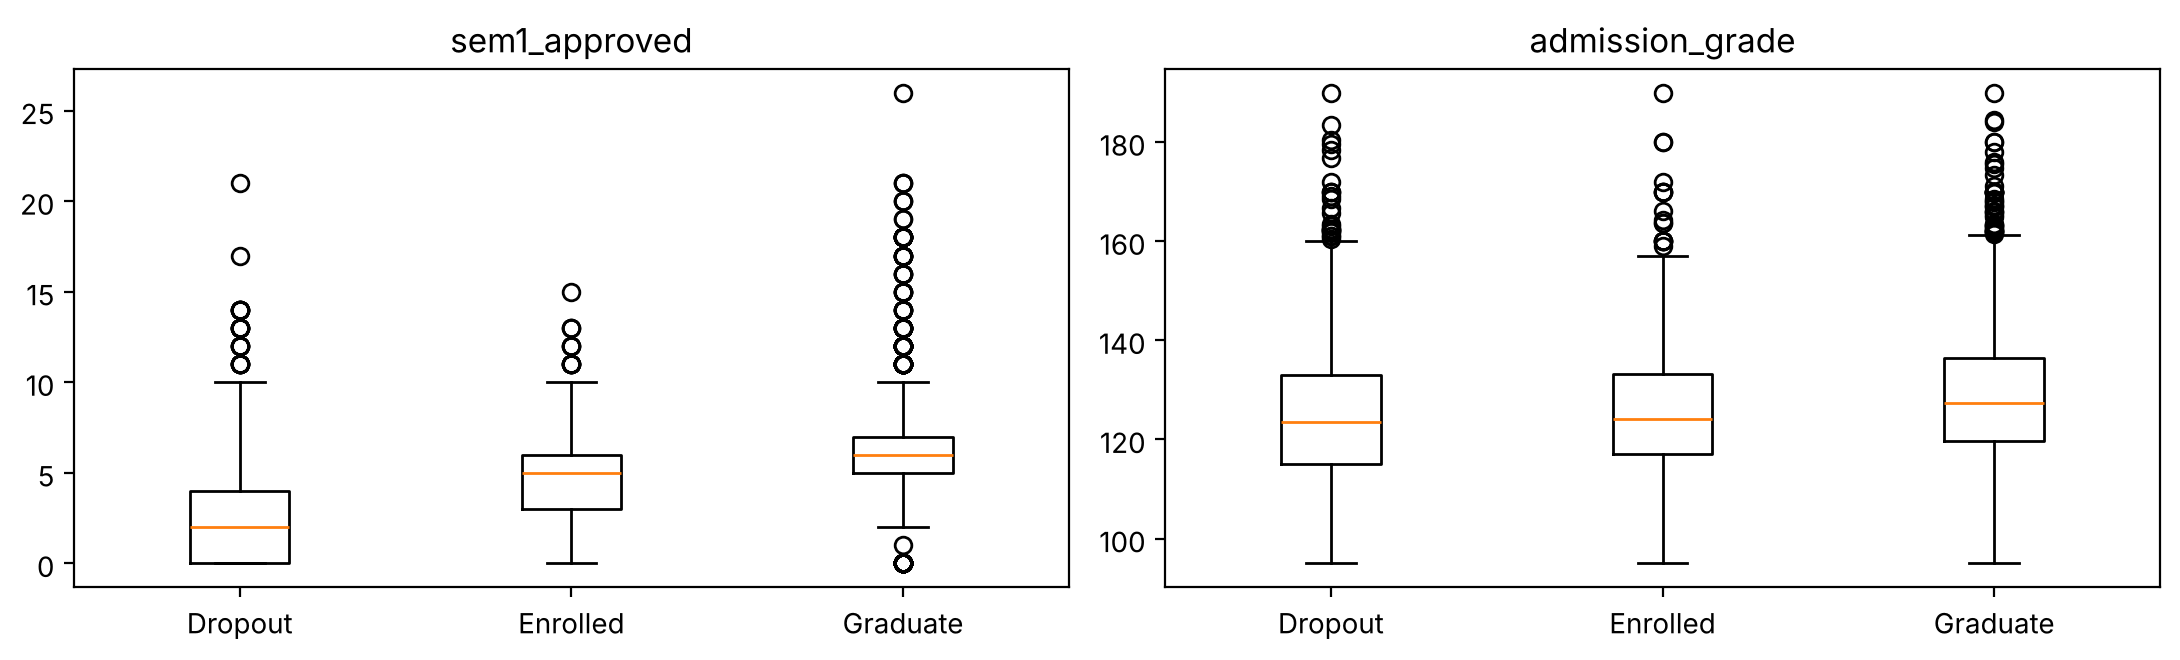

In [11]:
fig,ax=plt.subplots(1,2,figsize=(11,3.4))
for a,c in zip(ax,["sem1_approved","admission_grade"]):
    a.boxplot([d.loc[d[TARGET]==k,c] for k in CLASSES],tick_labels=CLASSES);a.set_title(c)
plt.tight_layout();plt.savefig("../report/figures/boxplots.png",dpi=150);plt.show()

## Summary – decisions for preprocessing
- No missing values and no duplicates; column names normalised to snake_case (typo *Nacionality* fixed, whitespace stripped: some copies of the UCI file contain a tab in a column name).
- 9 nominal codes → one-hot encoding, rare categories (< 20 students) grouped together.
- Outliers kept (valid values); numeric features standardised inside the pipeline.
- Zero grades → `no_grade` flag + `approval_rate`.
- Imbalanced target → stratified split, macro-F1, class weights.
- Risks: macro variables = cohort proxy; `tuition_fees_up_to_date` (87% dropout when 0) may be measured after enrollment.